In [ ]:
!pip install download

In [ ]:
from __future__ import absolute_import, division, print_function, unicode_literals

import seaborn as sns

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import os
from datetime import datetime

import pandas as pd

from download import download

mpl.rcParams['figure.figsize'] = (8, 6)
mpl.rcParams['axes.grid'] = False


In [ ]:
path = download('https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip', '/tmp/aq', kind="zip")


Replace is False and data exists, so doing nothing. Use replace=True to re-download the data.


In [ ]:
df = pd.read_csv('/tmp/aq/PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv', encoding='ISO-8859-1')

In [ ]:
!ls -alrt /tmp/aq/PRSA_Data_20130301-20170228

total 31780
drwxr-xr-x 3 root root    4096 Jan 24 08:06 ..
-rw-r--r-- 1 root root 2835916 Jan 24 08:06 PRSA_Data_Aotizhongxin_20130301-20170228.csv
-rw-r--r-- 1 root root 2722295 Jan 24 08:06 PRSA_Data_Changping_20130301-20170228.csv
-rw-r--r-- 1 root root 2675856 Jan 24 08:06 PRSA_Data_Dingling_20130301-20170228.csv
-rw-r--r-- 1 root root 2636684 Jan 24 08:06 PRSA_Data_Dongsi_20130301-20170228.csv
-rw-r--r-- 1 root root 2695860 Jan 24 08:06 PRSA_Data_Guanyuan_20130301-20170228.csv
-rw-r--r-- 1 root root 2654625 Jan 24 08:06 PRSA_Data_Gucheng_20130301-20170228.csv
-rw-r--r-- 1 root root 2641027 Jan 24 08:06 PRSA_Data_Huairou_20130301-20170228.csv
-rw-r--r-- 1 root root 2839705 Jan 24 08:06 PRSA_Data_Nongzhanguan_20130301-20170228.csv
-rw-r--r-- 1 root root 2620654 Jan 24 08:06 PRSA_Data_Shunyi_20130301-20170228.csv
-rw-r--r-- 1 root root 2655061 Jan 24 08:06 PRSA_Data_Tiantan_20130301-20170228.csv
-rw-r--r-- 1 root root 2659544 Jan 24 08:06 PRSA_Data_Wanliu_20130301-20170228.csv
drwxr-

In [ ]:
df

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
1,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
3,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
4,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,35060,2017,2,28,19,11.0,11.0,2.0,2.0,200.0,99.0,11.7,1008.9,-13.3,0.0,NNE,1.3,Dingling
35060,35061,2017,2,28,20,13.0,13.0,2.0,2.0,200.0,101.0,10.9,1009.0,-14.0,0.0,N,2.1,Dingling
35061,35062,2017,2,28,21,9.0,14.0,2.0,2.0,200.0,102.0,9.5,1009.4,-13.0,0.0,N,1.5,Dingling
35062,35063,2017,2,28,22,10.0,12.0,2.0,2.0,200.0,97.0,7.8,1009.6,-12.6,0.0,NW,1.4,Dingling


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34285 non-null  float64
 6   PM10     34408 non-null  float64
 7   SO2      34334 non-null  float64
 8   NO2      33830 non-null  float64
 9   CO       33052 non-null  float64
 10  O3       33850 non-null  float64
 11  TEMP     35011 non-null  float64
 12  PRES     35014 non-null  float64
 13  DEWP     35011 non-null  float64
 14  RAIN     35013 non-null  float64
 15  wd       34924 non-null  object 
 16  WSPM     35021 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [ ]:
def convert_to_date(x):
  return datetime.strptime(x,'%Y %m %d %H')

In [ ]:
aq_df = pd.read_csv('/tmp/aq/PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv',parse_dates = [['year', 'month', 'day', 'hour']],date_parser=convert_to_date, keep_date_col=True)

<ipython-input-73-e5e6faaf8392>:1: FutureWarning:

The 'keep_date_col' keyword in pd.read_csv is deprecated and will be removed in a future version. Explicitly remove unwanted columns after parsing instead.

<ipython-input-73-e5e6faaf8392>:1: FutureWarning:

Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.

<ipython-input-73-e5e6faaf8392>:1: FutureWarning:

The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.



In [ ]:
aq_df

,year_month_day_hour,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
1,2013-03-01 01:00:00,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2,2013-03-01 02:00:00,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
3,2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
4,2013-03-01 04:00:00,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,2017-02-28 19:00:00,35060,2017,2,28,19,11.0,11.0,2.0,2.0,200.0,99.0,11.7,1008.9,-13.3,0.0,NNE,1.3,Dingling
35060,2017-02-28 20:00:00,35061,2017,2,28,20,13.0,13.0,2.0,2.0,200.0,101.0,10.9,1009.0,-14.0,0.0,N,2.1,Dingling
35061,2017-02-28 21:00:00,35062,2017,2,28,21,9.0,14.0,2.0,2.0,200.0,102.0,9.5,1009.4,-13.0,0.0,N,1.5,Dingling
35062,2017-02-28 22:00:00,35063,2017,2,28,22,10.0,12.0,2.0,2.0,200.0,97.0,7.8,1009.6,-12.6,0.0,NW,1.4,Dingling


In [ ]:
aq_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   year_month_day_hour  35064 non-null  datetime64[ns]
 1   No                   35064 non-null  int64         
 2   year                 35064 non-null  object        
 3   month                35064 non-null  object        
 4   day                  35064 non-null  object        
 5   hour                 35064 non-null  object        
 6   PM2.5                34285 non-null  float64       
 7   PM10                 34408 non-null  float64       
 8   SO2                  34334 non-null  float64       
 9   NO2                  33830 non-null  float64       
 10  CO                   33052 non-null  float64       
 11  O3                   33850 non-null  float64       
 12  TEMP                 35011 non-null  float64       
 13  PRES                 35014 non-

In [ ]:
aq_df['month'] = pd.to_numeric(aq_df['month'])

In [ ]:
aq_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   year_month_day_hour  35064 non-null  datetime64[ns]
 1   No                   35064 non-null  int64         
 2   year                 35064 non-null  object        
 3   month                35064 non-null  int64         
 4   day                  35064 non-null  object        
 5   hour                 35064 non-null  object        
 6   PM2.5                34285 non-null  float64       
 7   PM10                 34408 non-null  float64       
 8   SO2                  34334 non-null  float64       
 9   NO2                  33830 non-null  float64       
 10  CO                   33052 non-null  float64       
 11  O3                   33850 non-null  float64       
 12  TEMP                 35011 non-null  float64       
 13  PRES                 35014 non-

In [ ]:
print("Rows :",aq_df.shape[0])
print("Columns : ",aq_df.shape[1])
print("\n Features :\n ",aq_df.columns.tolist())
print("\n Missing values :",aq_df.isnull().any())
print("\n Unique values : \n ",aq_df.nunique)

Rows : 35064
Columns :  19

 Features :
  ['year_month_day_hour', 'No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

 Missing values : year_month_day_hour    False
No                     False
year                   False
month                  False
day                    False
hour                   False
PM2.5                   True
PM10                    True
SO2                     True
NO2                     True
CO                      True
O3                      True
TEMP                    True
PRES                    True
DEWP                    True
RAIN                    True
wd                      True
WSPM                    True
station                False
dtype: bool

 Unique values : 
  <bound method DataFrame.nunique of       year_month_day_hour     No  year  month day hour  PM2.5  PM10  SO2  NO2  \
0     2013-03-01 00:00:00      1  2013      3   1    0    4.0   4.0  3.0  NaN

In [ ]:
aq_df_non_indexed = aq_df.copy()

In [ ]:
aq_df = aq_df.set_index('year_month_day_hour')

In [ ]:
aq_df.index

DatetimeIndex(['2013-03-01 00:00:00', '2013-03-01 01:00:00',
               '2013-03-01 02:00:00', '2013-03-01 03:00:00',
               '2013-03-01 04:00:00', '2013-03-01 05:00:00',
               '2013-03-01 06:00:00', '2013-03-01 07:00:00',
               '2013-03-01 08:00:00', '2013-03-01 09:00:00',
               ...
               '2017-02-28 14:00:00', '2017-02-28 15:00:00',
               '2017-02-28 16:00:00', '2017-02-28 17:00:00',
               '2017-02-28 18:00:00', '2017-02-28 19:00:00',
               '2017-02-28 20:00:00', '2017-02-28 21:00:00',
               '2017-02-28 22:00:00', '2017-02-28 23:00:00'],
              dtype='datetime64[ns]', name='year_month_day_hour', length=35064, freq=None)

In [ ]:
aq_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
year_month_day_hour,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
2013-03-01 01:00:00,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2013-03-01 02:00:00,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
2013-03-01 04:00:00,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling


Displaying data from 2013/03/01 to 2013/03/05

In [ ]:
aq_df.loc['2013-03-01':'2013-03-05']

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
year_month_day_hour,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
2013-03-01 01:00:00,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2013-03-01 02:00:00,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
2013-03-01 04:00:00,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2013-03-05 19:00:00,116,2013,3,5,19,179.0,200.0,50.0,96.0,1600.0,82.0,7.7,1005.4,-7.6,0.0,NNE,0.2,Dingling
2013-03-05 20:00:00,117,2013,3,5,20,172.0,180.0,43.0,94.0,1899.0,82.0,6.3,1005.9,-7.3,0.0,NNE,0.7,Dingling
2013-03-05 21:00:00,118,2013,3,5,21,179.0,191.0,38.0,80.0,1700.0,82.0,5.6,1006.0,-7.3,0.0,NNE,0.2,Dingling


In [ ]:
aq_df.loc[pd.to_datetime('2013-03-01'):pd.to_datetime('2013-03-05')]

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
year_month_day_hour,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
2013-03-01 01:00:00,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2013-03-01 02:00:00,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
2013-03-01 04:00:00,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2013-03-04 20:00:00,93,2013,3,4,20,41.0,80.0,18.0,44.0,900.0,49.0,5.9,1013.4,-11.7,0.0,ENE,0.2,Dingling
2013-03-04 21:00:00,94,2013,3,4,21,60.0,74.0,18.0,38.0,800.0,50.0,4.9,1013.4,-11.7,0.0,ESE,0.8,Dingling
2013-03-04 22:00:00,95,2013,3,4,22,50.0,71.0,22.0,38.0,1000.0,45.0,4.0,1013.2,-11.6,0.0,E,0.6,Dingling


Displaying records from 2013 to 2015

In [ ]:
aq_df.loc['2013':'2015']

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
year_month_day_hour,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
2013-03-01 01:00:00,2,2013,3,1,1,7.0,7.0,3.0,NaN,200.0,80.0,-2.5,1021.3,-19.0,0.0,ENE,0.7,Dingling
2013-03-01 02:00:00,3,2013,3,1,2,5.0,5.0,3.0,2.0,200.0,79.0,-3.0,1021.3,-19.9,0.0,ENE,0.2,Dingling
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,3.0,NaN,200.0,79.0,-3.6,1021.8,-19.1,0.0,NNE,1.0,Dingling
2013-03-01 04:00:00,5,2013,3,1,4,5.0,5.0,3.0,NaN,200.0,81.0,-3.5,1022.3,-19.4,0.0,N,2.1,Dingling
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2015-12-31 19:00:00,24860,2015,12,31,19,85.0,95.0,12.0,73.0,1200.0,2.0,-0.6,1021.0,-9.5,0.0,NE,0.6,Dingling
2015-12-31 20:00:00,24861,2015,12,31,20,NaN,109.0,32.0,79.0,2900.0,2.0,-1.8,1021.2,-9.9,0.0,NW,1.1,Dingling
2015-12-31 21:00:00,24862,2015,12,31,21,80.0,100.0,35.0,81.0,3200.0,2.0,-1.6,1020.8,-9.7,0.0,NE,0.9,Dingling


In [ ]:
pm_data = aq_df['PM2.5']

In [ ]:
pm_data.head()

,PM2.5
year_month_day_hour,
2013-03-01 00:00:00,4.0
2013-03-01 01:00:00,7.0
2013-03-01 02:00:00,5.0
2013-03-01 03:00:00,6.0
2013-03-01 04:00:00,5.0


<Axes: xlabel='year_month_day_hour'>

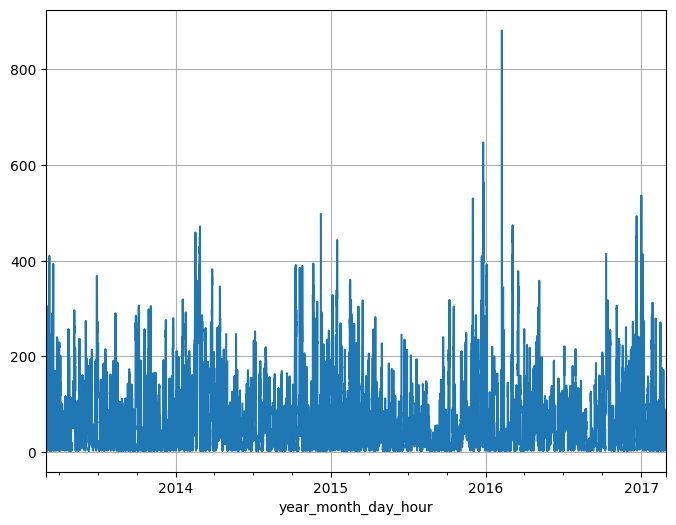

In [ ]:
pm_data.plot(grid=True)

plotting PM2.5 in the year 2015

<Axes: xlabel='year_month_day_hour'>

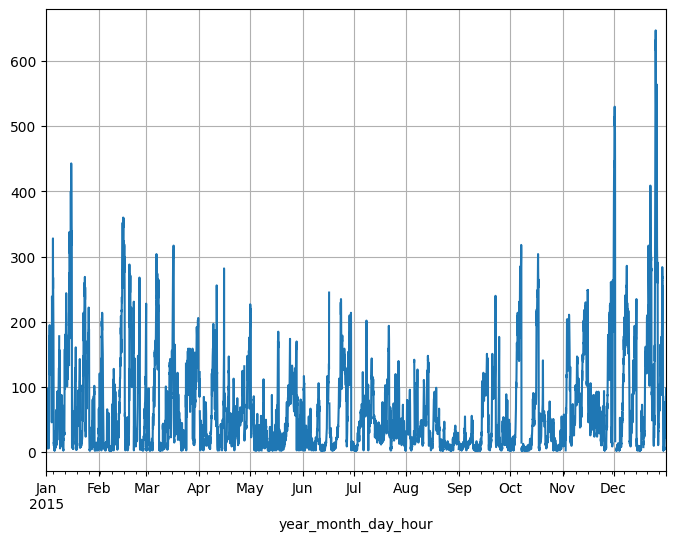

In [ ]:
aq_df.loc['2015']['PM2.5'].plot(grid=True)

<Axes: xlabel='year_month_day_hour'>

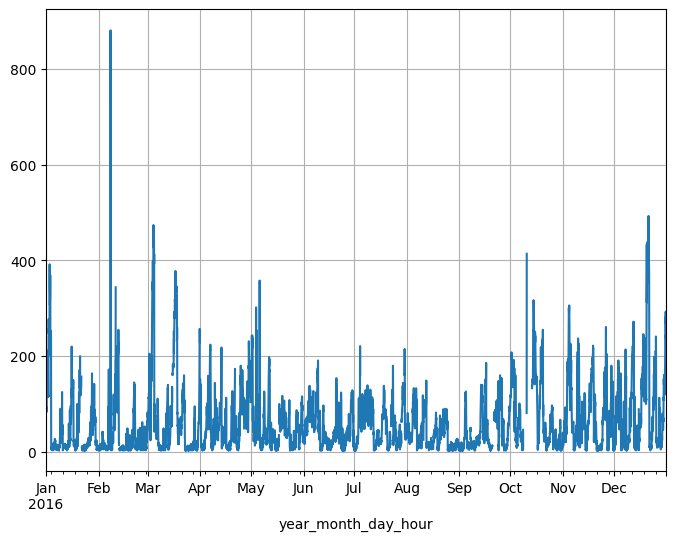

In [ ]:
#Pottig PM2.5 in 2016
aq_df.loc['2016']['PM2.5'].plot(grid=True)

We may want to display for all years with a slider

In [ ]:
import plotly.express as px
fig = px.line(aq_df_non_indexed,x='year_month_day_hour',y='PM2.5',title="PM2.5 Over the years")
fig.update_xaxes(rangeslider_visible = True)
fig.show()

In [ ]:
fig = px.line(aq_df_non_indexed,x='year_month_day_hour',y='PM2.5',title="PM 2.5 Distribution over the years")
fig.update_xaxes(
    rangeslider_visible = False,
    rangeselector = dict(
        buttons = list([
         dict(count = 1, label = "1y",step="year", stepmode = "backward"),
         dict(count = 2, label = "2y",step = "year",stepmode = "backward"),
         dict(count = 3, label = "3y",step = "year",stepmode = "backward"),
         dict(step = "all",label = "all")
        ]
        )
    )
)
fig.show()




PLotting the year 2014 and 2015 for the PM2.5 on the same axis

In [ ]:
df_2014 = aq_df.loc['2014'].reset_index()
df_2015 = aq_df.loc['2015'].reset_index()
df_2014['month_day_hour'] =df_2014.apply(lambda x : str(x('month')+"-"+x['day'],axis = 1))
df_2015['month_day_hour'] = df_2015.apply(lambda x: str(x('month')+"-"+x['day'],axis = 1))
df_2014
fig = px.line(df_2014,x ='month_day_hour',y='PM2.5',title = 'PM2.5 in 2014')
fig.show()

TypeError: 'Series' object is not callable

In [ ]:
df_2014= aq_df.loc['2014'].reset_index()
df_2015 = aq_df['2015'].reset_index()
df_2014['month_day_hour']=df_2014.apply(lambda x : str(x['month'])+"-"+x['day'],axis=1)
df_2015['month_day_hour']=df_2015.apply(lambda x : str(x['month'])+"-"+x['day'],axis=1)
plt.plot(df_2014['month_day_hour'], df_2014['PM2.5'])
plt.plot(df_2015['month_day_hour'], df_2015['PM2.5'])
plt.legend(['2014', '2015'])
plt.xlabel('Month')
plt.ylabel('PM2.5')
plt.title('Air Quality plot for the year 2014 and 2015')

KeyError: '2014'

In [ ]:
aq_df['2014':'2016'][['month','PM2.5']].groupby('month').describe()

PM2.5                                                       
        count       mean         std  min   25%   50%     75%    max
month                                                               
1      2173.0  70.285274   75.913587  3.0  12.0  38.0  113.00  443.0
2      1978.0  86.389282  105.603069  3.0  10.0  33.0  132.00  881.0
3      2212.0  80.193852   87.889440  3.0  13.0  47.0  123.25  474.0
4      2105.0  67.963325   56.430235  3.0  25.0  54.0   95.00  346.0
5      2188.0  47.994378   44.843130  3.0  16.0  35.0   67.00  358.0
6      2119.0  46.655403   43.877349  3.0  13.0  31.0   69.00  245.0
7      2205.0  61.671474   50.926149  3.0  21.0  48.0   91.00  252.0
8      2206.0  41.364869   37.279312  3.0  13.0  29.0   60.00  217.0
9      2074.0  45.356123   43.235331  3.0  11.0  27.0   78.00  240.0
10     2081.0  82.586257   92.234361  3.0  13.0  43.0  124.00  414.0
11     2141.0  77.500140   71.720648  3.0  20.0  56.0  112.00  394.0
12     2186.0  87.990851  104.677021  3.0  11.0  48.5  135.00  647.0

In [ ]:
aq_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 35064 entries, 2013-03-01 00:00:00 to 2017-02-28 23:00:00
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  object 
 2   month    35064 non-null  int64  
 3   day      35064 non-null  object 
 4   hour     35064 non-null  object 
 5   PM2.5    34285 non-null  float64
 6   PM10     34408 non-null  float64
 7   SO2      34334 non-null  float64
 8   NO2      33830 non-null  float64
 9   CO       33052 non-null  float64
 10  O3       33850 non-null  float64
 11  TEMP     35011 non-null  float64
 12  PRES     35014 non-null  float64
 13  DEWP     35011 non-null  float64
 14  RAIN     35013 non-null  float64
 15  wd       34924 non-null  object 
 16  WSPM     35021 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(2), object(5)
memory usage: 6.1+ MB


In [ ]:
df_2015.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   year_month_day_hour  8760 non-null   datetime64[ns]
 1   No                   8760 non-null   int64         
 2   year                 8760 non-null   object        
 3   month                8760 non-null   int64         
 4   day                  8760 non-null   object        
 5   hour                 8760 non-null   object        
 6   PM2.5                8651 non-null   float64       
 7   PM10                 8665 non-null   float64       
 8   SO2                  8653 non-null   float64       
 9   NO2                  8635 non-null   float64       
 10  CO                   8631 non-null   float64       
 11  O3                   8603 non-null   float64       
 12  TEMP                 8727 non-null   float64       
 13  PRES                 8727 non-nul

Plotting subplots for Temp and PM2.5 for the year 2015

array([<Axes: xlabel='year_month_day_hour'>,
       <Axes: xlabel='year_month_day_hour'>], dtype=object)

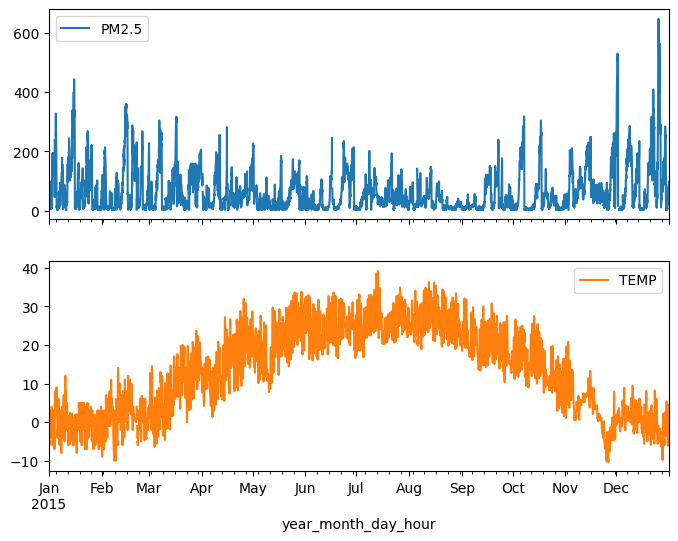

In [ ]:
aq_df.loc['2015'][['PM2.5','TEMP']].plot(subplots = True)

Plotting PM2.5 and TEMP histograms

array([[<Axes: title={'center': 'PM2.5'}>,
        <Axes: title={'center': 'TEMP'}>]], dtype=object)

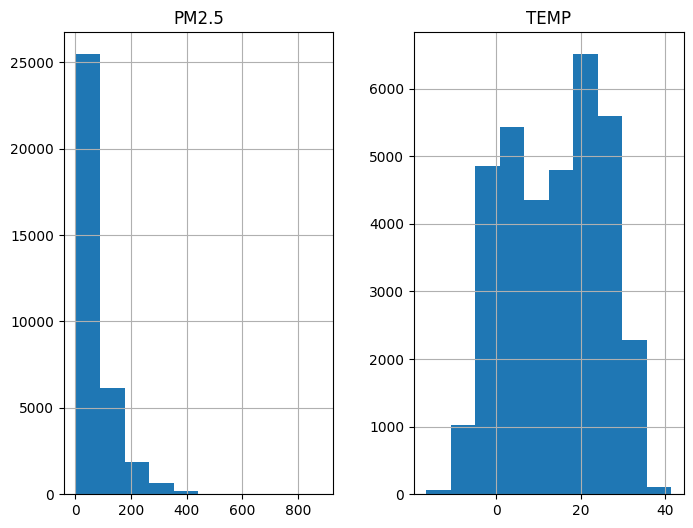

In [ ]:
aq_df[['PM2.5',"TEMP"]].hist()

Plotting a density plots for temperazture

<Axes: ylabel='Density'>

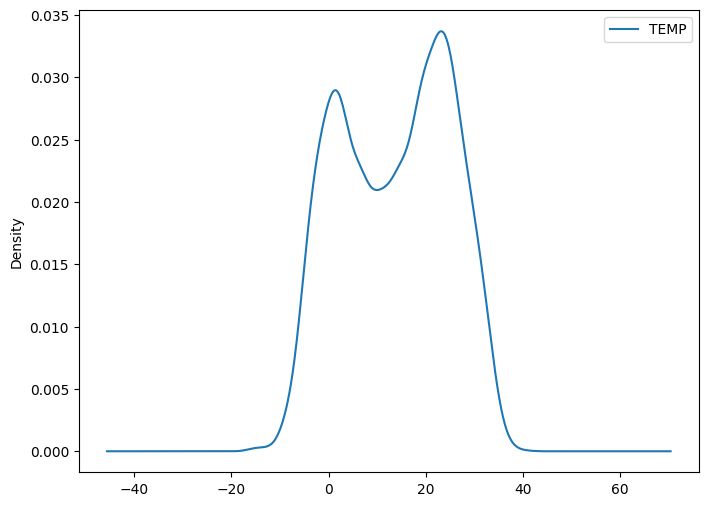

In [ ]:
aq_df[['TEMP']].plot(kind = 'density')

Plotting an autocorrelation plot for lag = 1

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

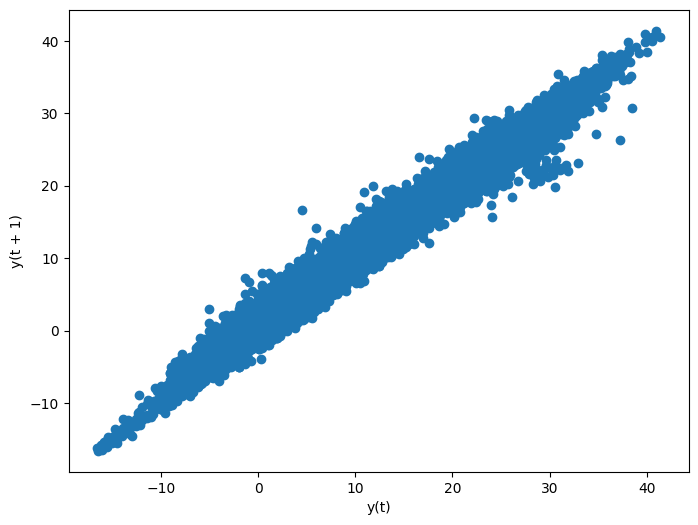

In [ ]:
pd.plotting.lag_plot(aq_df['TEMP'],lag = 1)

For lag 10

<Axes: xlabel='y(t)', ylabel='y(t + 10)'>

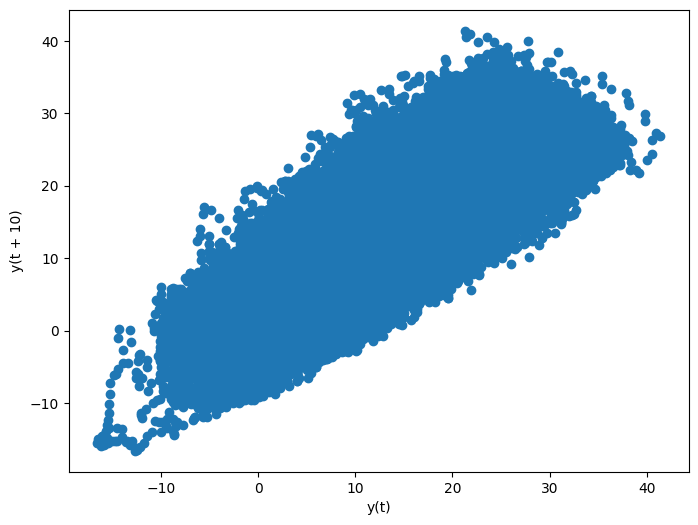

In [ ]:
pd.plotting.lag_plot(aq_df['TEMP'],lag = 10)

Lag plot where lag = 8640

<Axes: xlabel='y(t)', ylabel='y(t + 8640)'>

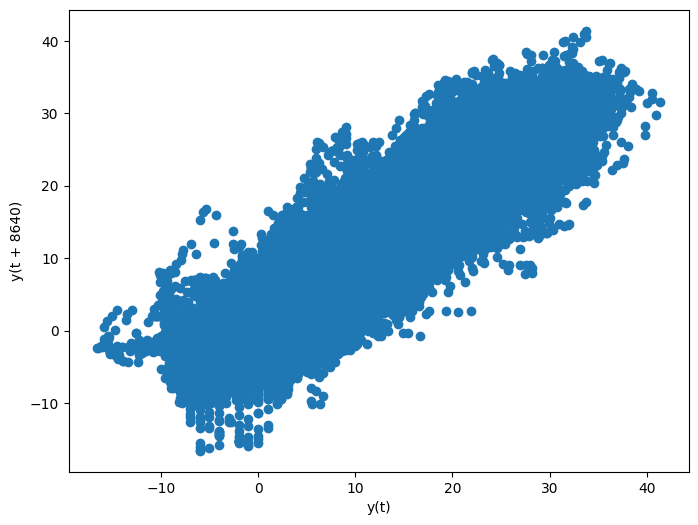

In [ ]:
pd.plotting.lag_plot(aq_df['TEMP'],lag = 8640)

For lag = 2150

<Axes: xlabel='y(t)', ylabel='y(t + 2150)'>

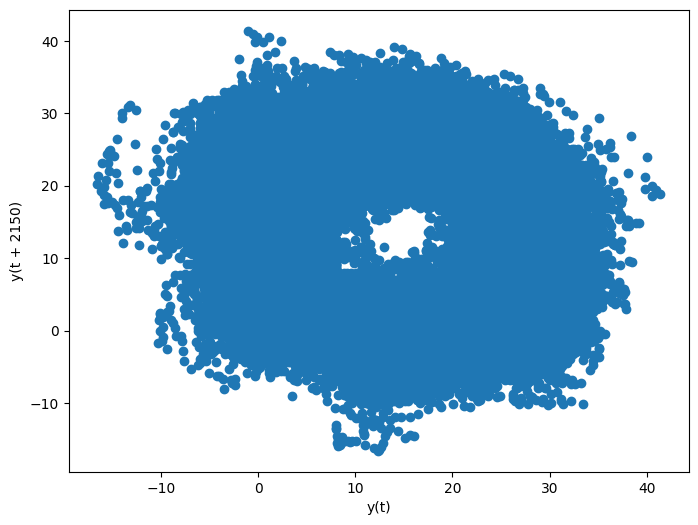

In [ ]:
pd.plotting.lag_plot(aq_df['TEMP'],lag = 2150)

In [ ]:
aq_df_2015 = aq_df.loc['2015']

array([<Axes: xlabel='year_month_day_hour'>,
       <Axes: xlabel='year_month_day_hour'>,
       <Axes: xlabel='year_month_day_hour'>], dtype=object)

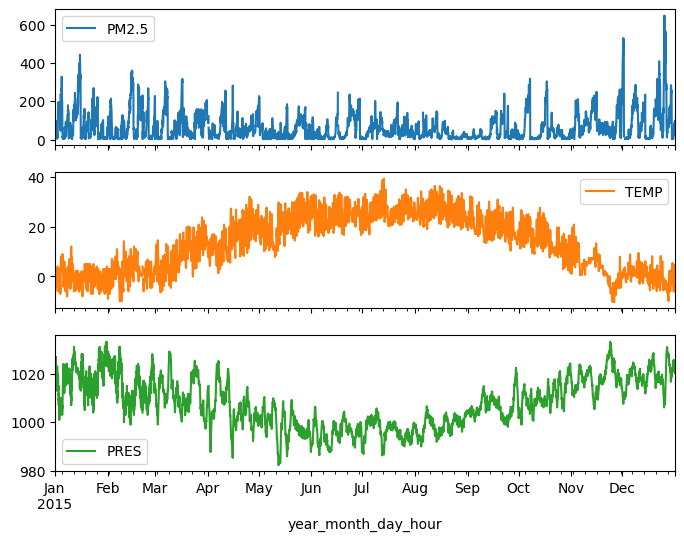

In [ ]:
pm_data_2015 = aq_df_2015[['PM2.5','TEMP','PRES']]
pm_data_2015.plot(subplots = True)

array([<Axes: xlabel='year_month_day_hour'>,
       <Axes: xlabel='year_month_day_hour'>,
       <Axes: xlabel='year_month_day_hour'>,
       <Axes: xlabel='year_month_day_hour'>], dtype=object)

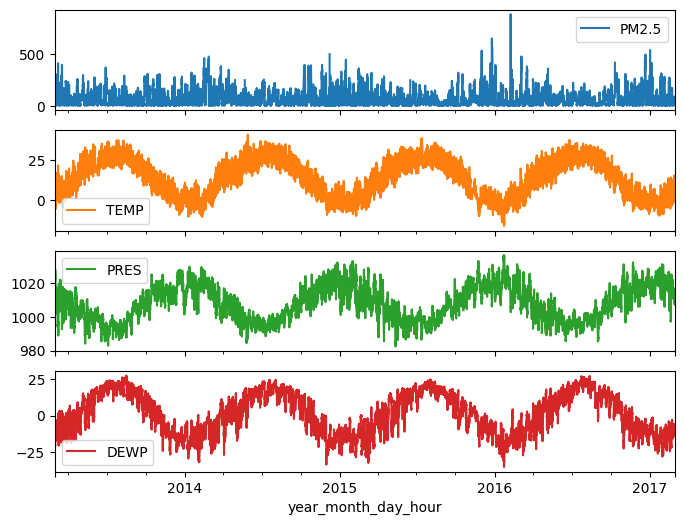

In [ ]:
multi_data = aq_df[['PM2.5',"TEMP","PRES","DEWP"]]
multi_data.plot(subplots = True)

Handling Missing Values

In [ ]:
#checking for missing values
aq_df.isnull().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,779
PM10,656
SO2,730
NO2,1234
CO,2012


Plotting a pairplot for our data columns (so2,No2,C0,PM2.5)

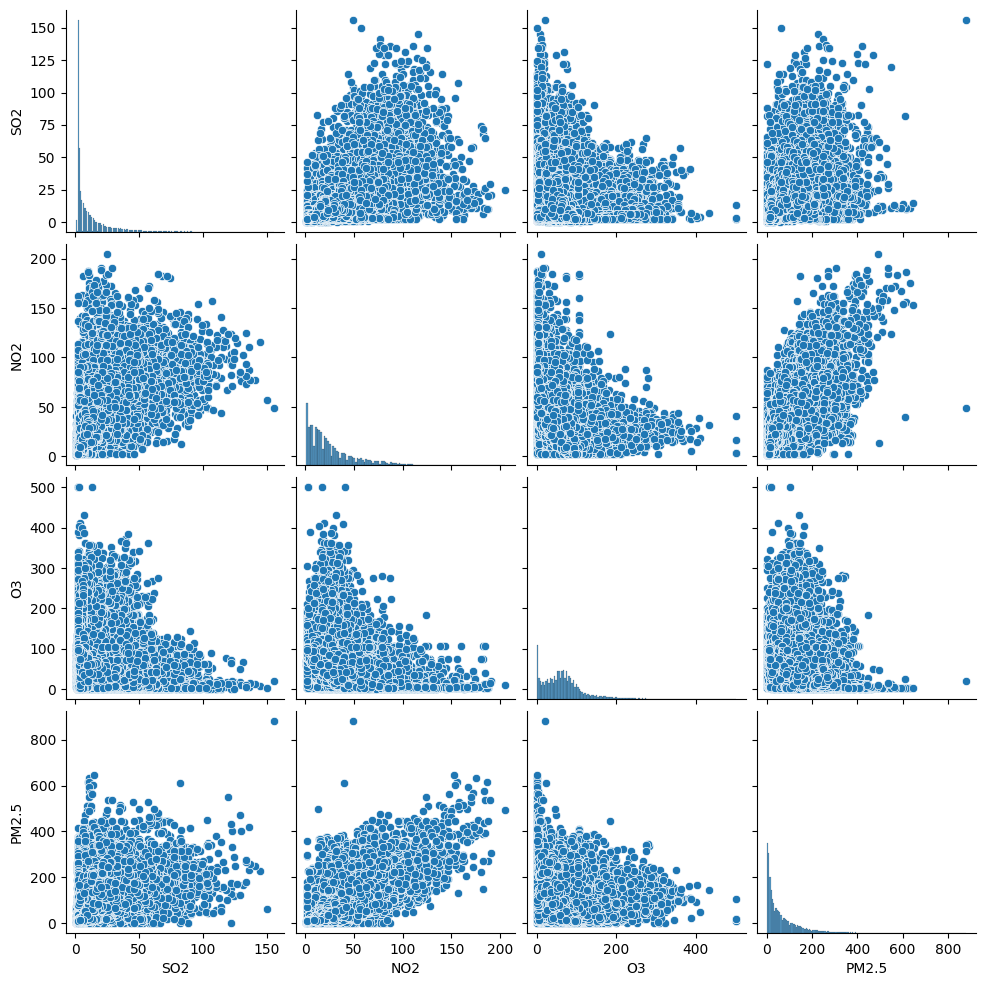

In [ ]:
import seaborn as sns
sns.pairplot(aq_df[['SO2','NO2',"O3","PM2.5"]])
plt.show()

Carrying out Pearson Correlation to our dataset

In [ ]:
aq_corr = aq_df[['SO2','NO2',"O3","PM2.5"]].corr(method = "pearson")
aq_corr

,SO2,NO2,O3,PM2.5
SO2,1.000000,0.610433,-0.182096,0.475117
NO2,0.610433,1.000000,-0.373625,0.718170
O3,-0.182096,-0.373625,1.000000,-0.100542
PM2.5,0.475117,0.718170,-0.100542,1.000000


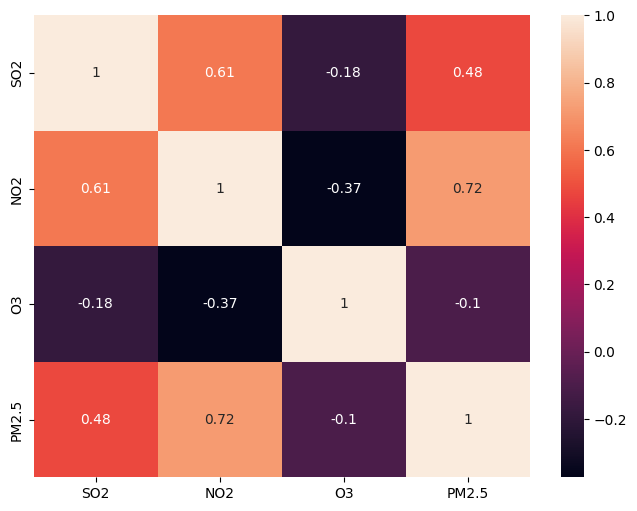

In [ ]:
#plotting a heatmap for our data
sns.heatmap(aq_corr,annot = True)
plt.show()

In [ ]:
aq_df.groupby('wd').agg(mean = ('PM2.5','mean'),median =('PM2.5','median'),MAX = ('PM2.5','max'),MIN = ('PM2.5','min'))

,mean,median,MAX,MIN
wd,,,,
E,88.623363,70.0,434.0,3.0
ENE,77.685514,56.5,647.0,3.0
ESE,96.492276,78.5,632.0,3.0
N,57.546221,29.0,536.0,3.0
NE,57.390083,32.0,530.0,3.0
NNE,53.946239,26.0,881.0,3.0
NNW,62.790775,33.0,548.0,3.0
NW,52.769116,21.0,535.0,3.0
S,72.497281,52.0,511.0,3.0


Plotting autocorrelation plots for our data

In [ ]:
aq_df_na = aq_df.copy()
aq_df_na = aq_df_na.dropna()

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

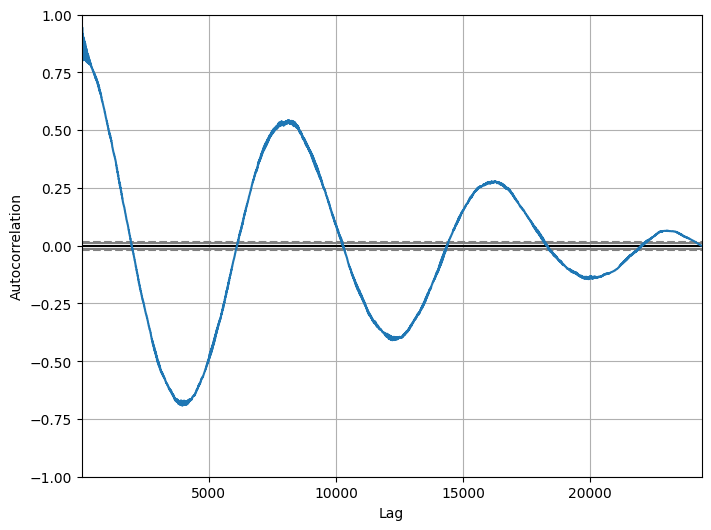

In [ ]:
pd.plotting.autocorrelation_plot(aq_df_na['2014':'2016']['TEMP'])

Resampling our data to monthly

In [ ]:
aq_df_na['TEMP'].resample("1m").mean()

<ipython-input-124-0a1ffa3236fe>:1: FutureWarning:

'm' is deprecated and will be removed in a future version, please use 'ME' instead.



,TEMP
year_month_day_hour,
2013-03-31,6.039970
2013-04-30,12.208494
2013-05-31,21.886386
2013-06-30,23.752827
2013-07-31,27.405079
2013-08-31,27.228465
2013-09-30,20.482500
2013-10-31,NaN
2013-11-30,5.434524


<ipython-input-126-8b05e32e8eef>:1: FutureWarning:

'm' is deprecated and will be removed in a future version, please use 'ME' instead.



<Axes: xlabel='Lag', ylabel='Autocorrelation'>

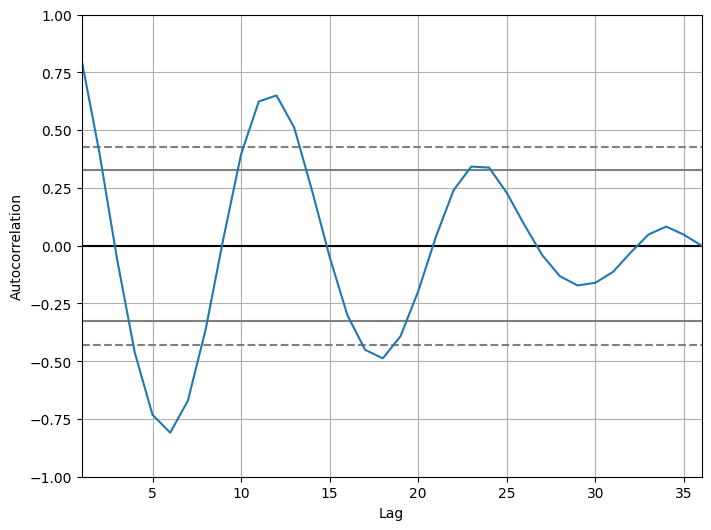

In [ ]:
pd.plotting.autocorrelation_plot(aq_df_na['2014':'2016']['TEMP'].resample("1m").mean())

What about for the PM2.5 how will it look like after resampling for one month for the year 2014 to 2016

<ipython-input-130-ee4aae4f00b3>:1: FutureWarning:

'm' is deprecated and will be removed in a future version, please use 'ME' instead.



<Axes: xlabel='Lag', ylabel='Autocorrelation'>

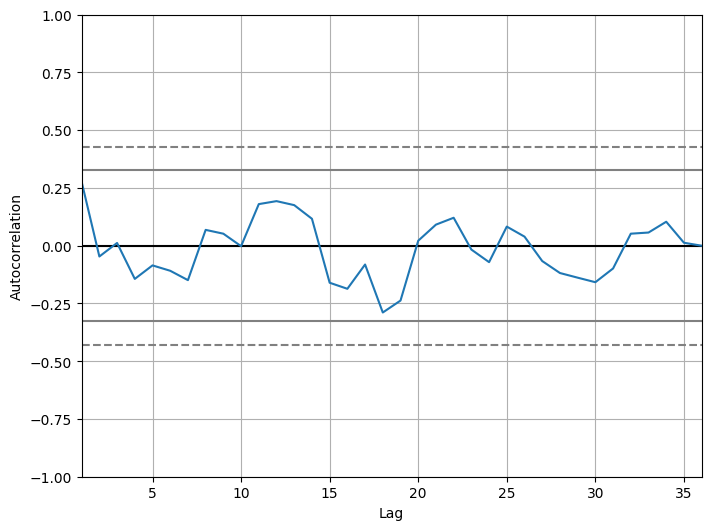

In [ ]:
pd.plotting.autocorrelation_plot(aq_df_na['2014':'2016']['PM2.5'].resample("1m").mean())



---

